In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from time import perf_counter
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED = 2026 #REPEAT SAME STARTING WEIGHTS, TO EVALUATE IF MODEL IS ACTUALLY LEARNING AND NOT GETTING LUCKY WITH GOOD WEIGHTS
LOOKBACK = 7
EPOCHS = 50
BATCH_SIZE = 32

COMMAND TO RUN IN VSCODE TERMINAL arch -arm64 ~/tf-m1/bin/python -m jupyterlab
Cell 1 Explanation
Sets imports, and basic hyper-parameters like lookback, epoch and batch size
batch size = 32 means the model uses 32 7 day windows and predicts the 8th day for each, calculates error then updates weights.
epochs = 50 means go through the entire dataset (batch by batch 50 times)


In [2]:
with open("saugeenday_dataset.tsf", "r") as f:
    data_line = next(line.strip() for line in f if line.startswith("T1:"))

series_name, start_text, values_text = data_line.split(":")
values = np.array([
    float(v) if v != "?" else np.nan
    for v in values_text.split(",")
])

start_date = pd.to_datetime(start_text, format="%Y-%m-%d %H-%M-%S")
#Line below starts at Jan 1 1915, adds one day per measurement
#and creates as many dates as there are measurements
dates = pd.date_range(start=start_date, periods=len(values), freq="D")

df = pd.DataFrame({"Flow": values}, index=dates)
df.index.name = "Date"

print("Source: https://zenodo.org/records/4656058")
print("Target: daily mean Saugeen River flow at Walkerton, in m³/s")
print("Frequency: daily | Resampling: none | Forecast horizon: 1 day")
print("Coverage:", df.index.min().date(), "to", df.index.max().date())
print("Observations:", len(df))
print("Missing flow values:", df.Flow.isna().sum())
print("Duplicate timestamps:", df.index.duplicated().sum())

expected_dates = pd.date_range(df.index.min(), df.index.max(), freq="D")
print("Gaps in reconstructed dates:", len(expected_dates.difference(df.index)))
print("Dates are reconstructed from the TSF start date and daily frequency.")
print("Separate timestamps are unavailable to independently verify gaps.")

display(df.head())

Source: https://zenodo.org/records/4656058
Target: daily mean Saugeen River flow at Walkerton, in m³/s
Frequency: daily | Resampling: none | Forecast horizon: 1 day
Coverage: 1915-01-01 to 1979-12-31
Observations: 23741
Missing flow values: 0
Duplicate timestamps: 0
Gaps in reconstructed dates: 0
Dates are reconstructed from the TSF start date and daily frequency.
Separate timestamps are unavailable to independently verify gaps.


,Flow
Date,
1915-01-01,11.5
1915-01-02,10.8
1915-01-03,13.7
1915-01-04,13.7
1915-01-05,14.4


Cell 2 Explanation
Code above reads the river flow file, gives each measurement a date, and displays basic checks on the data.
Frequency: One measurement per day
ReSampling: Keep original measurement, no observations made at higher or lower freqeuncies
Coverage: Temporal span of dataset
Observations: Number of flow values
No Missing flow values
No duplicate timestamps (days)
No Gaps (No missing days)

Original TSF file says values are daily, Code assumes this to be true.
Prints the first five days of flow.




In [3]:
series = df["Flow"]
n = len(series)

train_end = int(0.60 * n) 
val_end = int(0.80 * n)

train_raw = series.iloc[:train_end].copy() #60% train
val_raw = series.iloc[train_end:val_end].copy() #20% validation
test_raw = series.iloc[val_end:].copy() #20% test

split_table = pd.DataFrame([ #Display splits
    {
        "Split": name,
        "Start": s.index.min().date(),
        "End": s.index.max().date(),
        "Days": len(s)
    }
    for name, s in [
        ("Train", train_raw),
        ("Validation", val_raw),
        ("Test", test_raw)
    ]
])

display(split_table)

,Split,Start,End,Days
0,Train,1915-01-01,1953-12-30,14244
1,Validation,1953-12-31,1966-12-30,4748
2,Test,1966-12-31,1979-12-31,4749


Cell 3 Explanation

Code above splits data into training, validation and test sets, dividing into chronological temporal chunks

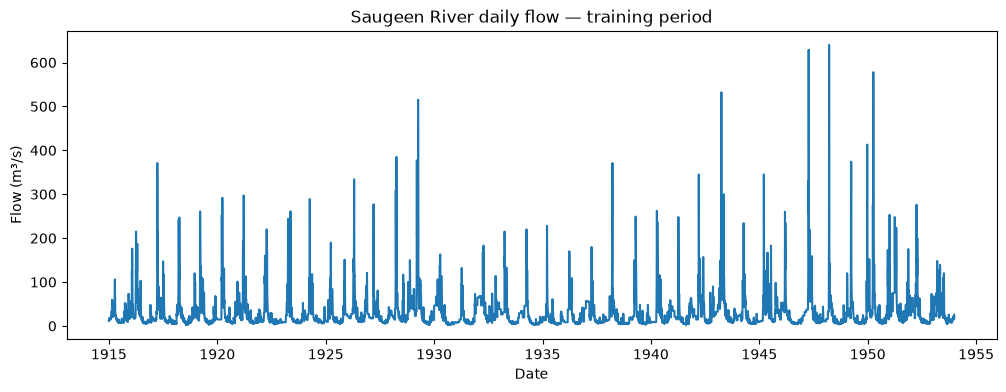

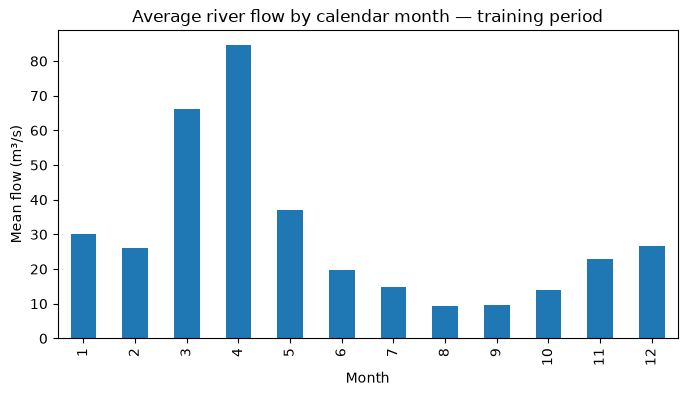

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(train_raw.index, train_raw)
plt.title("Saugeen River daily flow — training period")
plt.xlabel("Date")
plt.ylabel("Flow (m³/s)")
plt.show()

monthly_mean = train_raw.groupby(train_raw.index.month).mean()

plt.figure(figsize=(8, 4))
monthly_mean.plot(kind="bar")
plt.title("Average river flow by calendar month — training period")
plt.xlabel("Month")
plt.ylabel("Mean flow (m³/s)")
plt.show()

Cell 4 Explanation
Creates two plots
One of Daily river flow
River flow has occassional large spikes with no clear long term or upward or downward trend. This indicates either seasonality or cyclic behaviour, these spikes suggest the code might struggle to learn high flow days due to the sudden, high magnitude and abrupt variant behaviour.
One of Average river flow per month.
Seasonal pattern becomes far more apparent, with flow being highest in March-April and lowest in August-September, the current model uses only previous seven days of flow without monthly information, so this pattern is not explicitly incorporated.

In [5]:
# Forward fill uses past observations only.
# This dataset has no missing values, so nothing needs filling.
train = train_raw.ffill()
#allows missing first val reading to use last training reading
val = pd.concat([train.iloc[-1:], val_raw]).ffill().iloc[1:]
#same logic for test
test = pd.concat([val.iloc[-1:], test_raw]).ffill().iloc[1:]

#ensure no data is missing
assert train.notna().all() and val.notna().all() and test.notna().all()

# Fit the scaler on training data only.
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train.values.reshape(-1, 1)).ravel()
val_scaled = scaler.transform(val.values.reshape(-1, 1)).ravel()
test_scaled = scaler.transform(test.values.reshape(-1, 1)).ravel()

print("Imputation: forward fill; no values needed filling.")
print("Training mean:", scaler.mean_[0])
print("Training standard deviation:", scaler.scale_[0])

Imputation: forward fill; no values needed filling.
Training mean: 30.09040297669194
Training standard deviation: 39.32398644240527


Cell 5 Explanation

We don't have missing values, but assuming we did or if we were to get access to an augmented dataset, this code snippet would handle that.
We use standard scaler because the size of the input numbers affects how much the model's weights change during training. Scaling helps make those changes more stable, so learning can be easier.
Output demonstrates as before no missing values and spits out the training mean and standard deviation we are using for scaling purposes.

In [6]:
def make_windows(values, lookback):
    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])

    return np.asarray(X), np.asarray(y)


X_train, y_train = make_windows(train_scaled, LOOKBACK)
X_val, y_val = make_windows(val_scaled, LOOKBACK)
X_test, y_test = make_windows(test_scaled, LOOKBACK)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Each input contains 7 daily flows; its target is the next day's flow.")

Train: (14237, 7) (14237,)
Validation: (4741, 7) (4741,)
Test: (4742, 7) (4742,)
Each input contains 7 daily flows; its target is the next day's flow.


Cell 6 Explanation

Code above creates Inputs and outputs from our dataset with the lookback we defined at the top. The code turns the flwo readings into training exampels where seven days of flow are the input (X) and the following day's actual flow is the answer (y)
The output demonstrates the number of 7 day windows for each test/val/test set. The windows are overlapping so for example
days 1-7:8 is one window and days 2-8:9 is another.

In [7]:
def inverse_1d(values):
    return scaler.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    ).ravel()


val_actual = inverse_1d(y_val)


def score_model(name, predictions, parameters, training_seconds):
    return {
        "Model": name,
        "MAE": mean_absolute_error(val_actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(val_actual, predictions)),
        "Parameters": parameters,
        "Training_seconds": training_seconds
    }


# Predict tomorrow's flow using today's flow.
val_naive = inverse_1d(X_val[:, -1])

# The naive model has no fitted parameters or training step.
results = [score_model("Naive", val_naive, 0, 0.0)]

display(pd.DataFrame(results))

,Model,MAE,RMSE,Parameters,Training_seconds
0,Naive,4.290171,12.426237,0,0.0


Cell 7 Explanation

Code above creates and evaluates a simple baseline for model comparison, it's prediction model is simply that today's river flow will equal tomorrow's river flow.
And calcualtes a MAE and RMSE for this simple model.

In [8]:
import torch
from torch import nn
from copy import deepcopy

# Keep the baseline and replace any earlier neural-network results.
results = results[:1] #THE RESULTS FROM THE NAIVE BASELINE BEFORE


def build_mlp(units=32): 
    return nn.Sequential(
        nn.Linear(LOOKBACK, units),
        nn.ReLU(),
        nn.Linear(units, 1)
    )

#THE MODEL RECEIVES 7 DAYS. EACH FILTER PROCESSES THOSE 7 DAYS IN OVERLAPPING
#REGIONS OF 3

def build_cnn(filters=8, kernel_size=3):
    return nn.Sequential(
        nn.Conv1d(1, filters, kernel_size, padding=kernel_size // 2),
        nn.ReLU(),
        nn.MaxPool1d(2),
        nn.Flatten(),
        nn.Linear(filters * (LOOKBACK // 2), 16),
        nn.ReLU(),
        nn.Linear(16, 1)
    )


def train_model(model, train_inputs, val_inputs, lr=0.001): #TRAIN MODEL
    train_x = torch.as_tensor(train_inputs, dtype=torch.float32)
    train_y = torch.as_tensor(y_train, dtype=torch.float32).reshape(-1, 1)
    val_x = torch.as_tensor(val_inputs, dtype=torch.float32)
    val_y = torch.as_tensor(y_val, dtype=torch.float32).reshape(-1, 1)
    #ABOVE SETS THE TRAINING AND VALIDATION EXAMPLES
    
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    #LOSS AND BACKPROP METHODS

    best_loss = float("inf") #KEEP TRACK OF LOWEST VALIDATION ERROR
    best_weights = deepcopy(model.state_dict()) #GO BACK TO THAT MODEL EVEN IF NOT CURRENT ONE
    patience_count = 0 #NUMBER OF CONSECUTIVE EPOCHS WITHOUT IMPORVEMENT
    start = perf_counter() #MEASURE TRAINING TIME

    for epoch in range(EPOCHS):
        model.train()

        # Chronological batches: no shuffling.
        for i in range(0, len(train_x), BATCH_SIZE):
            batch_x = train_x[i:i + BATCH_SIZE]
            batch_y = train_y[i:i + BATCH_SIZE]

            optimizer.zero_grad()
            loss = loss_fn(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(val_x), val_y).item()

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= 5:
                break

    model.load_state_dict(best_weights)
    model.eval()

    return epoch + 1, perf_counter() - start


def predict_model(model, inputs):
    model.eval()
    with torch.no_grad():
        x = torch.as_tensor(inputs, dtype=torch.float32)
        return model(x).numpy().ravel()

Cell 8 Explanation

Training MLP...
Epochs trained: 31


,Model,MAE,RMSE,Parameters,Training_seconds
0,MLP,3.741,10.561,289,2.638


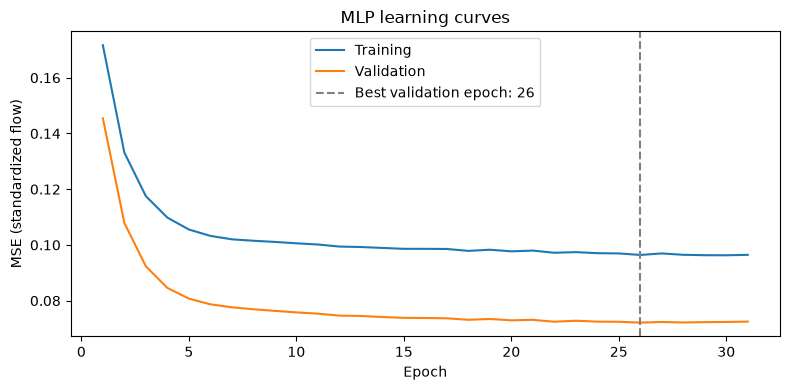

In [9]:
# Keep the baseline when rerunning these cells.
results = results[:1]


def train_model(model, train_inputs, val_inputs, lr=0.001):
    train_x = torch.as_tensor(train_inputs, dtype=torch.float32)
    train_y = torch.as_tensor(y_train, dtype=torch.float32).reshape(-1, 1)
    val_x = torch.as_tensor(val_inputs, dtype=torch.float32)
    val_y = torch.as_tensor(y_val, dtype=torch.float32).reshape(-1, 1)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    history = {"train_mse": [], "val_mse": []}
    best_loss = float("inf")
    best_weights = deepcopy(model.state_dict())
    patience_count = 0
    start = perf_counter()

    for epoch in range(EPOCHS):
        model.train()

        # Chronological batches: no shuffling.
        for i in range(0, len(train_x), BATCH_SIZE):
            batch_x = train_x[i:i + BATCH_SIZE]
            batch_y = train_y[i:i + BATCH_SIZE]

            optimizer.zero_grad()
            loss = loss_fn(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

        # Evaluate both losses using the weights at this epoch's end.
        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(train_x), train_y).item()
            val_loss = loss_fn(model(val_x), val_y).item()

        history["train_mse"].append(train_loss)
        history["val_mse"].append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1
            if patience_count >= 5:
                break

    model.load_state_dict(best_weights)
    model.eval()

    return len(history["val_mse"]), perf_counter() - start, history


def plot_learning_curves(history, title):
    epochs = np.arange(1, len(history["val_mse"]) + 1)
    best_epoch = int(np.argmin(history["val_mse"])) + 1

    plt.figure(figsize=(8, 4))
    plt.plot(epochs, history["train_mse"], label="Training")
    plt.plot(epochs, history["val_mse"], label="Validation")
    plt.axvline(
        best_epoch, color="gray", linestyle="--",
        label=f"Best validation epoch: {best_epoch}"
    )
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("MSE (standardized flow)")
    plt.legend()
    plt.tight_layout()
    plt.show()


torch.manual_seed(SEED)
mlp = build_mlp()

print("Training MLP...", flush=True)
mlp_epochs, mlp_seconds, mlp_history = train_model(
    mlp, X_train, X_val
)

mlp_pred = inverse_1d(predict_model(mlp, X_val))

mlp_result = score_model(
    "MLP",
    mlp_pred,
    sum(p.numel() for p in mlp.parameters() if p.requires_grad),
    mlp_seconds
)

results = [results[0], mlp_result]

print("Epochs trained:", mlp_epochs)
display(pd.DataFrame([mlp_result]).round(3))
plot_learning_curves(mlp_history, "MLP learning curves")

Cell 9 Explanation

CNN input shapes: (14237, 1, 7) (4741, 1, 7)
Training CNN...
Epochs trained: 50


,Model,MAE,RMSE,Parameters,Training_seconds
0,CNN,4.056,10.725,449,18.708


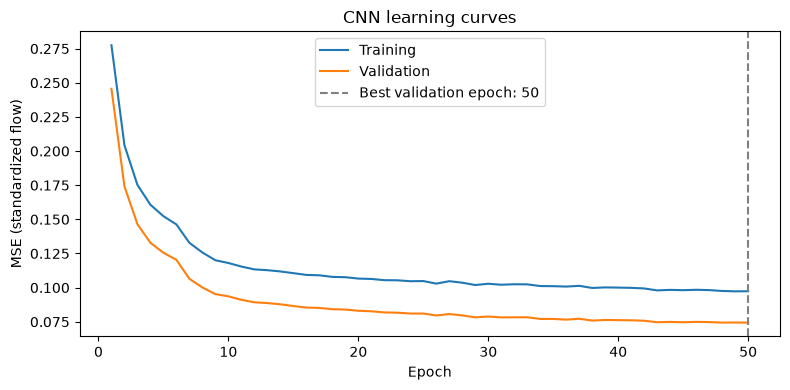

In [10]:
# PyTorch Conv1d expects: samples, channels, time steps.
X_train_cnn = X_train[:, np.newaxis, :]
X_val_cnn = X_val[:, np.newaxis, :]

print("CNN input shapes:", X_train_cnn.shape, X_val_cnn.shape)

torch.manual_seed(SEED)
cnn = build_cnn()

print("Training CNN...", flush=True)
cnn_epochs, cnn_seconds, cnn_history = train_model(
    cnn, X_train_cnn, X_val_cnn
)

cnn_pred = inverse_1d(predict_model(cnn, X_val_cnn))

cnn_result = score_model(
    "CNN",
    cnn_pred,
    sum(p.numel() for p in cnn.parameters() if p.requires_grad),
    cnn_seconds
)

results = [results[0], mlp_result, cnn_result]

print("Epochs trained:", cnn_epochs)
display(pd.DataFrame([cnn_result]).round(3))
plot_learning_curves(cnn_history, "CNN learning curves")

Cell 10 Explanation

MLP
Both errors fall sharply during the first few epochs, then flatten, showing that the model learns quickly but gains little from further training. Its best validation result occuring at epoch 26. It retains quite high MAE and RMSE.

CNN
Both erorrs decrease throughout training, with the best validaiton result at epoch 50. There is no sustained rise in validaiton error, so the graph shows no signs of overfitting. However it has higher MAE and RMSE.

WHICH IS BEST
MLP has better performance on error measurements, has lower training time and uses fewer parametes.
Key takeaways is that both could benefit from changes in architecture.

MLP's stall with more epochs means more layers could improve training (it is currently very simple)
CNN still learning at epoch 50 indicates that continued training could continue to improve performance.

Tune: MLP | Objective: lowest validation RMSE
Budget: 4 configurations, up to 50 epochs each
Early-stopping patience: 5


,units,lr
0,16,0.010
1,16,0.001
2,32,0.010
3,32,0.001


Training configuration 1: {'units': 16, 'lr': 0.01}
Training configuration 2: {'units': 16, 'lr': 0.001}
Training configuration 3: {'units': 32, 'lr': 0.01}
Training configuration 4: {'units': 32, 'lr': 0.001}


,Model,MAE,RMSE,Parameters,Training_seconds,units,lr,Epochs_trained,Best_epoch
0,Tuned MLP,3.721,10.386,145,4.108,16,0.001,50,48
1,Tuned MLP,3.741,10.561,289,2.566,32,0.001,31,26
2,Tuned MLP,4.464,11.624,289,0.576,32,0.010,7,2
3,Tuned MLP,4.163,11.884,145,0.848,16,0.010,10,5


Best configuration: {'units': 16, 'lr': 0.001}
Total grid-search training seconds: 8.098


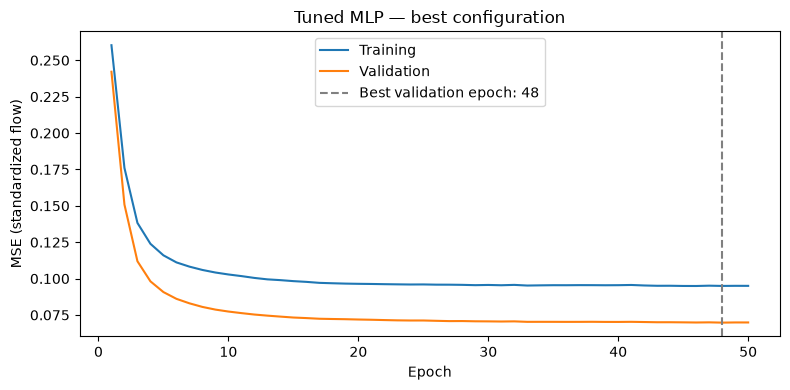

In [11]:
family = min(
    [mlp_result, cnn_result],
    key=lambda row: row["RMSE"]
)["Model"]

if family == "MLP":
    configurations = [
        {"units": units, "lr": lr}
        for units, lr in product([16, 32], [0.01, 0.001])
    ]
    train_inputs, val_inputs = X_train, X_val
else:
    configurations = [
        {"filters": filters, "kernel_size": kernel}
        for filters, kernel in product([8, 16], [3, 7])
    ]
    train_inputs, val_inputs = X_train_cnn, X_val_cnn

print("Tune:", family, "| Objective: lowest validation RMSE")
print(f"Budget: {len(configurations)} configurations, "
      f"up to {EPOCHS} epochs each")
print("Early-stopping patience: 5")
display(pd.DataFrame(configurations))

grid_results = []
best_grid_rmse = float("inf")

for number, config in enumerate(configurations, start=1):
    print(f"Training configuration {number}: {config}", flush=True)
    torch.manual_seed(SEED)

    if family == "MLP":
        candidate = build_mlp(units=config["units"])
        lr = config["lr"]
    else:
        candidate = build_cnn(**config)
        lr = 0.001

    epochs_trained, seconds, history = train_model(
        candidate, train_inputs, val_inputs, lr=lr
    )

    pred = inverse_1d(predict_model(candidate, val_inputs))

    row = score_model(
        f"Tuned {family}",
        pred,
        sum(p.numel() for p in candidate.parameters() if p.requires_grad),
        seconds
    )
    row.update(config)
    row["Epochs_trained"] = epochs_trained
    row["Best_epoch"] = int(np.argmin(history["val_mse"])) + 1
    grid_results.append(row)

    if row["RMSE"] < best_grid_rmse:
        best_grid_rmse = row["RMSE"]
        best_config = config.copy()
        best_model = deepcopy(candidate)
        best_history = deepcopy(history)

grid_results = (
    pd.DataFrame(grid_results)
    .sort_values("RMSE", kind="stable")
    .reset_index(drop=True)
)

best_tuned = grid_results.iloc[0]

display(grid_results.round(3))
print("Best configuration:", best_config)
print(
    "Total grid-search training seconds:",
    round(grid_results["Training_seconds"].sum(), 3)
)

plot_learning_curves(
    best_history, f"Tuned {family} — best configuration"
)

Cell 11 Explanation

Performs Grid Search

In [12]:
comparison = pd.DataFrame(
    results + [{key: best_tuned[key] for key in results[0]}]
)

baseline_rmse = results[0]["RMSE"]

comparison["RMSE_improvement_percent"] = (
    100 * (baseline_rmse - comparison["RMSE"]) / baseline_rmse
)

comparison = comparison.sort_values(
    "RMSE", kind="stable"
).reset_index(drop=True)

print("VALIDATION comparison — MAE and RMSE in m³/s")
print("Positive improvement means lower RMSE than the naive baseline.")
print("Training time is for each individual model fit.")
print("Total grid-search training time is reported in cell 11.")
print("The test set remains reserved for final evaluation.")

display(comparison.round(3))

VALIDATION comparison — MAE and RMSE in m³/s
Positive improvement means lower RMSE than the naive baseline.
Training time is for each individual model fit.
Total grid-search training time is reported in cell 11.
The test set remains reserved for final evaluation.


,Model,MAE,RMSE,Parameters,Training_seconds,RMSE_improvement_percent
0,Tuned MLP,3.721,10.386,145,4.108,16.419
1,MLP,3.741,10.561,289,2.638,15.014
2,CNN,4.056,10.725,449,18.708,13.693
3,Naive,4.290,12.426,0,0.000,0.000


Cell 12 Explanation

Compares the tuned MLP, the original MLP (LR = 0.001), original CNN and Naive model

In [13]:
winner = comparison.iloc[0]

if winner["Model"] == "Naive":
    print(
        f"Conclusion: the naive baseline had the lowest validation "
        f"RMSE ({winner['RMSE']:.3f} m³/s). "
        "Neither the initial nor the tuned neural models achieved "
        "a lower validation RMSE."
    )
else:
    print(
        f"Conclusion: {winner['Model']} had the lowest validation "
        f"RMSE ({winner['RMSE']:.3f} m³/s), with "
        f"{winner['RMSE_improvement_percent']:.2f}% improvement "
        "over the naive baseline."
    )

print("\nLearning-curve evidence:")

for name, history in [
    ("MLP", mlp_history),
    ("CNN", cnn_history),
    (f"Tuned {family}", best_history)
]:
    best_index = int(np.argmin(history["val_mse"]))
    final_index = len(history["val_mse"]) - 1

    print(
        f"{name}: best validation epoch = {best_index + 1}; "
        f"epochs trained = {final_index + 1}."
    )

    if (
        history["train_mse"][final_index]
        < history["train_mse"][best_index]
        and history["val_mse"][final_index]
        > history["val_mse"][best_index]
    ):
        print(
            "Training loss fell while validation loss rose after "
            "the best epoch, suggesting overfitting. "
            "The best validation weights were restored."
        )
    else:
        print(
            "Comparing the best and final epochs does not show "
            "training loss falling while validation loss rises. "
            "This does not rule out overfitting."
        )

print(
    "\nUnresolved risk: average errors may hide poor forecasts during "
    "high-flow peaks. Evaluate peak-flow errors separately next."
)

Conclusion: Tuned MLP had the lowest validation RMSE (10.386 m³/s), with 16.42% improvement over the naive baseline.

Learning-curve evidence:
MLP: best validation epoch = 26; epochs trained = 31.
Comparing the best and final epochs does not show training loss falling while validation loss rises. This does not rule out overfitting.
CNN: best validation epoch = 50; epochs trained = 50.
Comparing the best and final epochs does not show training loss falling while validation loss rises. This does not rule out overfitting.
Tuned MLP: best validation epoch = 48; epochs trained = 50.
Comparing the best and final epochs does not show training loss falling while validation loss rises. This does not rule out overfitting.

Unresolved risk: average errors may hide poor forecasts during high-flow peaks. Evaluate peak-flow errors separately next.


Cell 13 Explanation

High Level Explanation

Conclusion: Tuned MLP was best but lots of room for improvement

Explore deeper and wider models: The MLP has one hidden layer and the CNN has one convolutional layer. Test additional layers and neurons to determine whether greater capacity improves prediciton accuracy, this should be the case considering our error curves do not demonstrate the canonical validation error uptick near end of training.

Represent the observed seasonality: The 7 day lookback provides limited historical context and does not explicitly identify the annual seasonal pattern observed in exploratory data analysis. Test longer lookbakcs and calendar featrues such as month or day of year, and also analyze data at different frequencies.

Expand the grid search. The current 2X2 grid explores only 2 neuron counts and 2 learning rates. Test more values and additional hyperparamters such as layer counts, activation functions, batch size, lookbacks, and patience.

Investigate longer CNN training: The CNN achieved its best valdiation result at the final epoch, suggesting that additional training deserves investigation, and that it might eventually outperform the MLP.

Allow more computation to pursue accuracy: We built the baseline arhcitecture and workflow, now we should investigate larger models and longer training times.

Use Validation results to control complexity: The curves show no clear signs of overfitting making larger models reasonable experiments to pursue. However this does not guarantee that increased complexity will improve performance, retain early stopping and compare validation errors.

Explore Other Patiences: Compare values such as 5, 10 and 15. A short patience is a risk as it can stop training during a temporary plateau. A longer patience gives improvement more time to resume.

AI was used to write the code once the architecture was established by the group, the code was reviewed to ensure it was doing what was intended, and the outputs were also reviewed. Minor adjustments were made by hand.